# Cas de référence : échantillon monolithique

Noms des campagnes : 
- `campagne_honey`
- `campagne_honey_CC`
- `campagne_honey_UR3_S13`
- `campagne_honey_UR3_S7`

## Mapping sans CC en fct de theta et la taille du motif

In [35]:
from classes import *
from funcData import *
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from math import *
import os 

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 100


campagnes = ['campagne_honey','campagne_carre','campagne_trian', 'campagne_hexac']
# Can be long the first time
data=read_data_from_campaigns(campagnes)
data_bulk = get_bulk_data(data)

Lecture des données réalisée en 2.50300s


[18.17, 94.22, 157.66, 145.24]


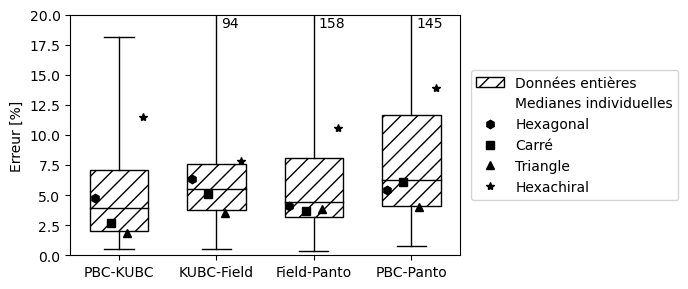

In [36]:
err = [[] for i in range(4)]

for _, test in data_bulk.items():
    err[0].append(test.get_err((0, 1)))
    err[1].append(test.get_err((1, 2)))
    err[2].append(test.get_err((2, 3)))
    err[3].append(test.get_err((0, 3)))
print([max(i) for i in err])

mean_err_per_geo = np.zeros((4, 4, max([len(c) for _, c in data.items()])))
mean_err_per_geo[:] = np.nan
counter = [0, 0, 0, 0]

for c_name, campagne in data.items():
    geo_idx = campagnes.index(c_name)
    for _, test in campagne.items():
        mean_err_per_geo[0, geo_idx, counter[geo_idx]] = test.get_err((0, 1))
        mean_err_per_geo[1, geo_idx, counter[geo_idx]] = test.get_err((1, 2))
        mean_err_per_geo[2, geo_idx, counter[geo_idx]] = test.get_err((2, 3))
        mean_err_per_geo[3, geo_idx, counter[geo_idx]] = test.get_err((0, 3))
        counter[geo_idx] += 1

mean_err_per_geo = np.nanquantile(mean_err_per_geo,0.5, axis=2).tolist()

plt.figure(figsize=(7, 3))
bp=plt.boxplot(err, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': False, 'hatch':'//'},widths=0.6)

# * Legende
nn = mlines.Line2D([], [], color='w', marker='*', linestyle='')
hexa = mlines.Line2D([], [], color='k', marker='h', linestyle='')
carre = mlines.Line2D([], [], color='k', marker='s', linestyle='')
trian = mlines.Line2D([], [], color='k', marker='^', linestyle='')
hc = mlines.Line2D([], [], color='k', marker='*', linestyle='')
plt.legend([bp['boxes'][0],nn, hexa,carre,trian,hc],['Données entières','Medianes individuelles','Hexagonal','Carré', 'Triangle', 'Hexachiral'],
           fancybox=True,loc='center left', bbox_to_anchor=(1.01, 0.5))


plt.ylim(top=20, bottom=0)
plt.ylabel('Erreur [%]')
plt.xticks(range(1, 5), ['PBC-KUBC',
                         'KUBC-Field',
                         'Field-Panto',
                         'PBC-Panto'])

plt.text(2.05,19.9,'94', va='top', ha='left')
plt.text(3.05,19.9,'158', va='top', ha='left')
plt.text(4.05,19.9,'145', va='top', ha='left')


markers = ['h', 's', '^', '*']
n=6 # Space between indivuals medians
for i_error, error in enumerate(mean_err_per_geo):
    for i_geo, geo in enumerate(error):
        plt.plot([i_error+1-(1/n+1/n/2)+1/n*i_geo], [geo], 'k'+markers[i_geo])


plt.tight_layout()
plt.savefig('images/mapping_error_glob.pdf')


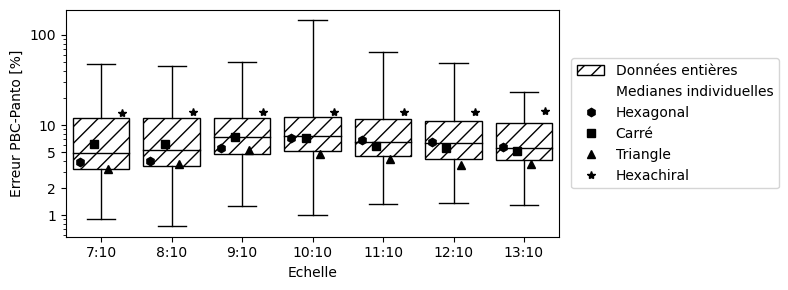

In [37]:

err = [[] for i in range(7)]

for test_id, test in data_bulk.items():
    err[int(test_id.split('_')[1])-7].append(test.get_err((0, 3)))

mean_err_per_geo = np.zeros((7, 4, max([len(c) for _, c in data.items()])))
mean_err_per_geo[:] = np.nan
counter = np.zeros((7,4))

for c_name, campagne in data.items():
    geo_idx = campagnes.index(c_name)
    for test_id, test in campagne.items():
        scale=int(test_id.split('_')[1])-7
        mean_err_per_geo[scale, geo_idx, int(counter[scale,geo_idx])] = test.get_err((0, 3))
        counter[scale,geo_idx] += 1

mean_err_per_geo = np.nanquantile(mean_err_per_geo,0.5, axis=2).tolist()

plt.figure(figsize=(8, 3))
bp=plt.boxplot(err, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': False, 'hatch':'//'},widths=0.8)

# * Legende
nn = mlines.Line2D([], [], color='w', marker='*', linestyle='')
hexa = mlines.Line2D([], [], color='k', marker='h', linestyle='')
carre = mlines.Line2D([], [], color='k', marker='s', linestyle='')
trian = mlines.Line2D([], [], color='k', marker='^', linestyle='')
hc = mlines.Line2D([], [], color='k', marker='*', linestyle='')
plt.legend([bp['boxes'][0],nn, hexa,carre,trian,hc],['Données entières','Medianes individuelles','Hexagonal','Carré', 'Triangle', 'Hexachiral'],
           fancybox=True,loc='center left', bbox_to_anchor=(1.01, 0.5))




markers = ['h', 's', '^', '*']
n=5 # Space between indivuals medians
for i_error, error in enumerate(mean_err_per_geo):
    for i_geo, geo in enumerate(error):
        plt.plot([i_error+1-(1/n+1/n/2)+1/n*i_geo], [geo], 'k'+markers[i_geo])

ax=plt.gca()
ax.set_yscale('log')
ax.set_yticks([1, 2,5,10,100])
ax.get_yaxis().set_major_formatter(mpl.ticker.ScalarFormatter())

plt.xlabel('Echelle')
plt.ylabel('Erreur PBC-Panto [%]')
plt.xticks(range(1, 8), ['7:10','8:10','9:10','10:10','11:10','12:10','13:10'])

plt.tight_layout()
plt.savefig('images/error_per_scale.pdf')

Lecture des données réalisée en 0.23570s


Text(0, 0.5, '$\\Delta(\\mathrm{PBC},\\mathrm{Panto})-\\Delta(\\mathrm{PBC},\\mathrm{Panto})_{CC}$')

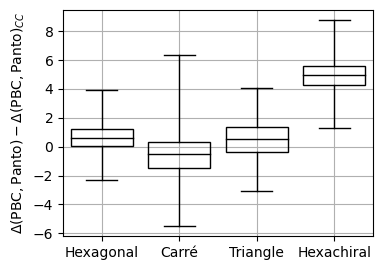

In [64]:

campagnes_CC = ['campagne_honey_CC','campagne_carre_CC','campagne_trian_CC', 'campagne_hexac_CC']
# Can be long the first time
data_CC=read_data_from_campaigns(campagnes_CC)
data_CC_bulk = get_bulk_data(data_CC)


amelioration=[[] for i in range(4)]
eoi=(0,3)

for c_name, campagne in data_CC.items():
    geo_idx = campagnes_CC.index(c_name)
    for test_id, test in campagne.items():
        try:
            ref=data_bulk[test_id.replace('CC','')]
        except:
            print(f'{test_id} non trouvé')
            continue
        amelioration[geo_idx].append(-(test.get_err(eoi)-ref.get_err(eoi)))


plt.figure(figsize=(4, 3))
bp=plt.boxplot(amelioration, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': False},widths=0.8)

plt.grid()

plt.xticks(range(1,5),['Hexagonal', 'Carré', 'Triangle', 'Hexachiral'])
plt.ylabel(r'$\Delta(\mathrm{PBC},\mathrm{Panto})-\Delta(\mathrm{PBC},\mathrm{Panto})_{CC}$')

Lecture des données réalisée en 0.44117s


Text(0, 0.5, '$\\Delta(\\mathrm{PBC},\\mathrm{Panto})-\\Delta(\\mathrm{PBC},\\mathrm{Panto})_{CC}$')

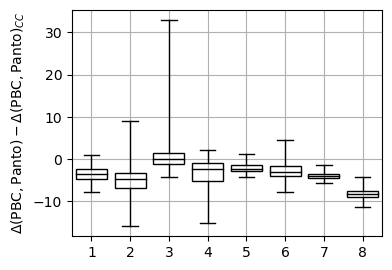

In [67]:

campagnes_R3 = ['campagne_honey_UR3_S7','campagne_honey_UR3_S13',
                'campagne_carre_UR3_S7','campagne_carre_UR3_S13',
                'campagne_trian_UR3_S7','campagne_trian_UR3_S13', 
                'campagne_hexac_UR3_S7','campagne_hexac_UR3_S13']
# Can be long the first time
data_R3=read_data_from_campaigns(campagnes_R3)



amelioration=[[] for i in range(8)]
eoi=(0,3)

for c_name, campagne in data_R3.items():
    geo_idx = campagnes_R3.index(c_name)
    for test_id, test in campagne.items():
        try:
            ref=data_bulk[test_id.replace('UR3','')]
        except:
            print(f'{test_id} non trouvé')
            continue
        amelioration[geo_idx].append(-(test.get_err(eoi)-ref.get_err(eoi)))


plt.figure(figsize=(4, 3))
bp=plt.boxplot(amelioration, patch_artist=True, whis=(0, 100), medianprops={
            'color': 'k'}, boxprops={'fill': False},widths=0.8)

plt.grid()


plt.ylabel(r'$\Delta(\mathrm{PBC},\mathrm{Panto})-\Delta(\mathrm{PBC},\mathrm{Panto})_{CC}$')